# 04 · Expression — EMT-transcription-factor axis along the trajectory

*(Renumbered from 06: Gate 2 = NO-GO / Gate 3 = NA means the manifold is neither
branching nor a shared developmental gradient, so the branching-only correlation
and modules notebooks are not produced — this unconditional expression notebook
follows signatures directly, as the protocol requires it for every dataset.)*

Puram 2017 overlays **SNAI1** (root) and **ZEB1** (terminus) as the two EMT-TFs
marking the ends of its trajectory. Per the **derive-don't-inherit** mandate we do
**not** inherit that pair: we score a candidate EMT-TF panel — the canonical
Snail/Zeb/Twist factors **plus the mesenchymal/neural-crest FOXC and PRRX
factors** — along *this* manifold's imposed readout axis and let the data choose
the most end-specific factor at each end. **Interpretation caveat (Gate-2 NO-GO):**
this axis is a fitted coordinate on an isotropic blob, not a developmental
trajectory, so any TF gradient below is a description of where these factors fall
on the manifold, **not** evidence of an EMT differentiation path. Deliverable:
`expression.pdf`.

In [ ]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [ ]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
os.makedirs(pth_fig, exist_ok=True)

### Load the rooted, signature-scored manifold

In [ ]:
adata = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']   # house linear layout
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('cells:', adata.shape[0], '| pseudotime range', round(t.min(),2), '->', round(t.max(),2))

cells: 7945 | pseudotime range 0.0 -> 8.84


### Derive the end-specific EMT-TFs (data-driven)
For each candidate TF we record the fraction of cells expressing it, its mean
expression in the early (root) vs late (terminus) pseudotime tercile, and its
Spearman correlation with the axis. The most negatively-correlated
sufficiently-expressed factor marks the root end; the most positively-correlated
marks the terminus. Factors below a 3% expression floor are too sparse to overlay.

In [ ]:
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
early = tn <= np.quantile(tn, 1/3); late = tn >= np.quantile(tn, 2/3)
X = adata[:,present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows = []
for j,g in enumerate(present):
    x = X[:,j]; expr = x > 0
    rho,p = spearmanr(tn, x)
    rows.append((g, round(expr.mean(),3), round(x[early].mean(),3),
                 round(x[late].mean(),3), round(rho,3)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_early','mean_late','rho_vs_t'])
df['end'] = np.where(df.mean_early > df.mean_late, 'EARLY(root)', 'LATE(terminus)')
df = df.sort_values('rho_vs_t')
print(df.to_string(index=False))
ok = df[df.frac_expr > 0.03]
early_tf = ok.sort_values('rho_vs_t').iloc[0]['TF']
late_tf  = ok.sort_values('rho_vs_t').iloc[-1]['TF']
print(f'\nderived pair: {early_tf} (early/root end) <-> {late_tf} (late/terminus end)')

    TF  frac_expr  mean_early  mean_late  rho_vs_t            end
  ZEB1      0.088       0.036      0.037     0.000 LATE(terminus)
 FOXC2      0.002       0.001      0.001     0.013 LATE(terminus)
 PRRX2      0.039       0.011      0.015     0.017 LATE(terminus)
TWIST1      0.008       0.001      0.004     0.024 LATE(terminus)
TWIST2      0.000       0.000      0.000     0.025 LATE(terminus)
 SNAI1      0.023       0.007      0.011     0.030 LATE(terminus)
 FOXC1      0.171       0.071      0.088     0.031 LATE(terminus)
 PRRX1      0.022       0.006      0.010     0.033 LATE(terminus)
  ZEB2      0.058       0.017      0.029     0.047 LATE(terminus)
 SNAI2      0.093       0.023      0.084     0.162 LATE(terminus)

derived pair: ZEB1 (early/root end) <-> SNAI2 (late/terminus end)


### EMT-TF expression overlay (deliverable)
House style adapted to the round-blob geometry: square panel (equal aspect),
axis left→right. The abundant late marker is drawn first so the sparser early
marker reads on top. `size=16` (consistent with every other Peng deliverable
panel). Each factor is thresholded at the upper quartile of expression among its
expressing cells, so only the strongest expressers show and the early (blue) /
late (red) regions separate.

overlay thresholds (upper quartile among expressers): {'ZEB1': 0.603, 'SNAI2': 0.73} | cells shown: {'ZEB1': 175, 'SNAI2': 184}
ZEB1: 8.8% expressing; 175 shown (upper quartile), mean axis position of shown cells = 0.54 (all cells = 0.49)
SNAI2: 9.3% expressing; 184 shown (upper quartile), mean axis position of shown cells = 0.73 (all cells = 0.49)
shown-cell axis separation (ZEB1 vs SNAI2) = 0.19
saved expression.pdf


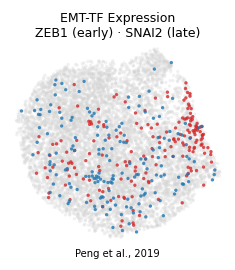

In [ ]:
xl = adata.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.05
def _vec(g):
    x = adata[:,g].X
    return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
thr = {}
for g in [early_tf, late_tf]:
    v = _vec(g); pos = v[v>0]; thr[g] = float(np.quantile(pos, 0.75)) if pos.size else 0.0
sel = {g: _vec(g) > thr[g] for g in [early_tf, late_tf]}
print('overlay thresholds (upper quartile among expressers):', {g: round(thr[g],3) for g in [early_tf, late_tf]},
      '| cells shown:', {g: int(sel[g].sum()) for g in [early_tf, late_tf]})
order = sorted([early_tf, late_tf], key=lambda g: -int(sel[g].sum()))
colors = {early_tf:'tab:blue', late_tf:'tab:red'}
fig, ax = plt.subplots(figsize=(2.5,2.1))
sc.pl.umap(adata, size=16, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[sel[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=16, alpha=.8, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py); ax.set_aspect('equal')
ax.set_title(f'EMT-TF Expression\n{early_tf} (early) · {late_tf} (late)', size=7.5)
ax.text(.5,-.08,'Peng et al., 2019', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight')
for g in [early_tf, late_tf]:
    m = sel[g]
    print(f'{g}: {(_vec(g)>0).mean()*100:.1f}% expressing; {int(m.sum())} shown (upper quartile), '
          f'mean axis position of shown cells = {tn[m].mean():.2f} (all cells = {tn.mean():.2f})')
sep = abs(tn[sel[late_tf]].mean() - tn[sel[early_tf]].mean())
print(f'shown-cell axis separation ({early_tf} vs {late_tf}) = {sep:.2f}')
print('saved expression.pdf')